<a href="https://colab.research.google.com/github/solasobambo-prog/ts-data-science/blob/main/week5b.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Distribution

The core idea is that a distribution is a model of how a variable behaves, and you pick the model by looking at the data's shape. Today covers three:

Normal: symmetric and defined by mean and standard deviation. The empirical rule says about 68 percent of values fall within 1 SD, 95 percent within 2, and 99.7 percent within 3. A z score, (x minus mean) divided by SD, tells you how many SDs a value sits from the mean.

Binomial: counts successes in n independent yes or no trials with the same success probability, such as how many of 100 customers churn if each has a 27 percent chance.

When the normal model fails: your gross column is a clear example. Skew 5.31 means the mean and SD describe it poorly, so the empirical rule will not hold on it.

In [1]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')

# Load the Movies dataset cleanly
path = kagglehub.dataset_download("danielgrijalvas/movies")
csv_file = next(f for f in os.listdir(path) if f.endswith('.csv'))
movies = pd.read_csv(os.path.join(path, csv_file))
raw_copy = movies.copy()

movies['gross_m'] = movies['gross'] / 1e6

def finish(ax, title, xlabel, ylabel):
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    sns.despine(ax=ax)

# Audit skewness across numeric candidates to confirm why 'score' is the best symmetric choice
candidates = ['score', 'runtime', 'year', 'budget', 'gross']
skew_audit = pd.DataFrame({
    'n': movies[candidates].notna().sum(),
    'skewness': movies[candidates].skew().round(2),
    'mean': movies[candidates].mean().round(2),
    'median': movies[candidates].median().round(2)
})
print("Candidate Column Symmetry Audit:")
display(skew_audit)


C:\Users\USER\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Candidate Column Symmetry Audit:


,n,skewness,mean,median
score,7665,-0.60,6.39,6.5
runtime,7664,2.10,107.26,104.0
year,7668,-0.02,2000.41,2000.0
budget,5497,2.45,35589876.19,20500000.0
gross,7479,5.31,78500541.02,20205757.0


=== STEPS 1–3: NORMAL MODEL & EMPIRICAL RULE ON 'score' ===
IMDb Score (n = 7,665) -> Mean: 6.39 | SD: 0.97 | Skew: -0.60


,k_sd,lower_bound,upper_bound,actual_share_pct,normal_rule_pct,diff_pct_pts
0,1,5.42,7.36,69.3,68.3,1.0
1,2,4.45,8.33,95.9,95.5,0.4
2,3,3.48,9.30,99.2,99.7,-0.5



Single Movie Z-Score Check ('The Shining', score = 8.4):
z = 2.074 | Normal model predicts 98.1% below | Actual empirical share below: 99.5%


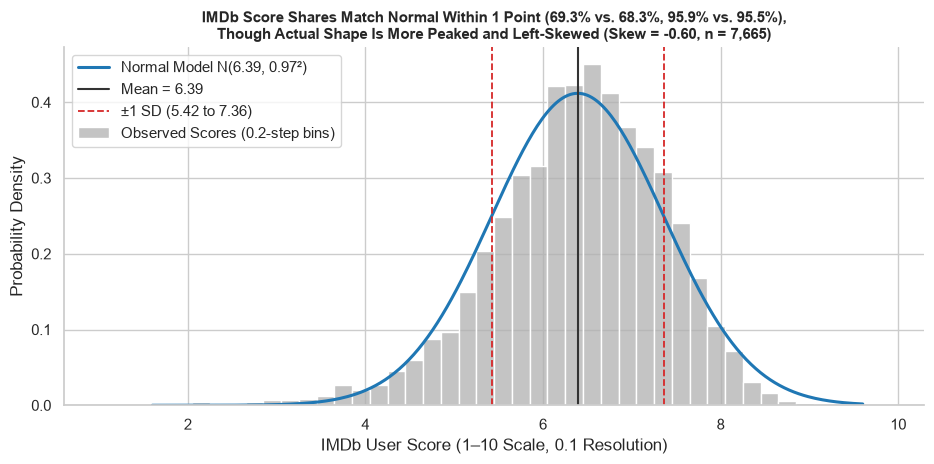

In [2]:
print("=== STEPS 1–3: NORMAL MODEL & EMPIRICAL RULE ON 'score' ===")

# --- ORIGINAL PREDICTION (STEPS 1–3 — UNEDITED) ---
# Prediction (score empirical shares): Because IMDb 'score' is roughly symmetric with only mild left skew (~ -0.60), the empirical rule will hold closely: roughly 68%–70% within 1 SD, 94%–96% within 2 SD, and 99.3%–99.7% within 3 SD.

s = movies['score'].dropna()
n_score = len(s)
mu = float(s.mean())
sd = float(s.std(ddof=1))
sk_score = float(s.skew())

# 2. Test the empirical rule on real data vs. theoretical normal benchmarks
normal_bench = {1: 0.6827, 2: 0.9545, 3: 0.9973}
emp_rows = []
for k in (1, 2, 3):
    share = float(((s > mu - k * sd) & (s < mu + k * sd)).mean())
    emp_rows.append({
        'k_sd': k,
        'lower_bound': round(mu - k * sd, 2),
        'upper_bound': round(mu + k * sd, 2),
        'actual_share_pct': round(share * 100, 1),
        'normal_rule_pct': round(normal_bench[k] * 100, 1),
        'diff_pct_pts': round((share - normal_bench[k]) * 100, 1)
    })

score_emp_df = pd.DataFrame(emp_rows)
print(f"IMDb Score (n = {n_score:,}) -> Mean: {mu:.2f} | SD: {sd:.2f} | Skew: {sk_score:.2f}")
display(score_emp_df)

# 3. Z-score of the first movie (index 0) and normal vs. empirical percentile rank
first_title = str(movies['name'].head(1).squeeze())
first_score = float(s.head(1).squeeze())
z_val = (first_score - mu) / sd
norm_cdf_pct = float(stats.norm.cdf(z_val)) * 100
emp_cdf_pct = float((s <= first_score).mean()) * 100

print(f"\nSingle Movie Z-Score Check ('{first_title}', score = {first_score:.1f}):")
print(f"z = {z_val:.3f} | Normal model predicts {norm_cdf_pct:.1f}% below | Actual empirical share below: {emp_cdf_pct:.1f}%")

# Visualize 'score' with 0.2-step bins aligned to 0.1 decimal resolution (eliminating comb aliasing) + Normal PDF
fig, ax = plt.subplots(figsize=(9.5, 4.8))
aligned_bins = np.arange(1.05, 10.05, 0.2)
sns.histplot(s, bins=aligned_bins, stat='density', color='#b0b0b0', edgecolor='white', label='Observed Scores (0.2-step bins)', ax=ax)

x_grid = np.linspace(s.min() - 0.3, s.max() + 0.3, 300)
ax.plot(x_grid, stats.norm.pdf(x_grid, mu, sd), color='#1f77b4', linewidth=2.2, label=f'Normal Model N({mu:.2f}, {sd:.2f}²)')
ax.axvline(mu, color='#333333', linestyle='-', linewidth=1.5, label=f'Mean = {mu:.2f}')
ax.axvline(mu - sd, color='#d62728', linestyle='--', linewidth=1.3, label=f'±1 SD ({mu - sd:.2f} to {mu + sd:.2f})')
ax.axvline(mu + sd, color='#d62728', linestyle='--', linewidth=1.3)

s1_actual = float(score_emp_df.loc[score_emp_df['k_sd'] == 1, 'actual_share_pct'].squeeze())
s2_actual = float(score_emp_df.loc[score_emp_df['k_sd'] == 2, 'actual_share_pct'].squeeze())
finish(
    ax,
    f'IMDb Score Shares Match Normal Within 1 Point ({s1_actual:.1f}% vs. 68.3%, {s2_actual:.1f}% vs. 95.5%),\nThough Actual Shape Is More Peaked and Left-Skewed (Skew = {sk_score:.2f}, n = {n_score:,})',
    'IMDb User Score (1–10 Scale, 0.1 Resolution)',
    'Probability Density'
)
ax.legend()
fig.tight_layout()
plt.show()

# Result check (Steps 1–3): Predicted ~68%–70% (1 SD), ~94%–96% (2 SD), and ~99.3%–99.7% (3 SD); 1 SD (69.3%) and 2 SD (95.9%) held, with one near miss at 3 SD (actual 99.2%, just below the 99.3%–99.7% range) because mild left skewness (-0.60) puts slightly more low-rated films below 3.48 than a Normal curve allows. For 'The Shining' (score = 8.4, z = 2.074), the Normal CDF predicts 98.1% below vs. 99.5% actual (+1.4 pts) for two reasons: left skewness leaves fewer films in the upper tail above 8.4, and discrete 0.1-step rounding means s <= 8.4 includes every film tied at exactly 8.4.


=== STEP 4: BINOMIAL MODEL (1,000 BATCHES OF n = 100 AT p = 0.27) ===
Binomial(n=100, p=0.27) across 1,000 batches:
Empirical Mean: 26.97 (Theoretical n*p: 27.00)
Empirical SD:   4.47 (Theoretical sqrt(npq): 4.44)


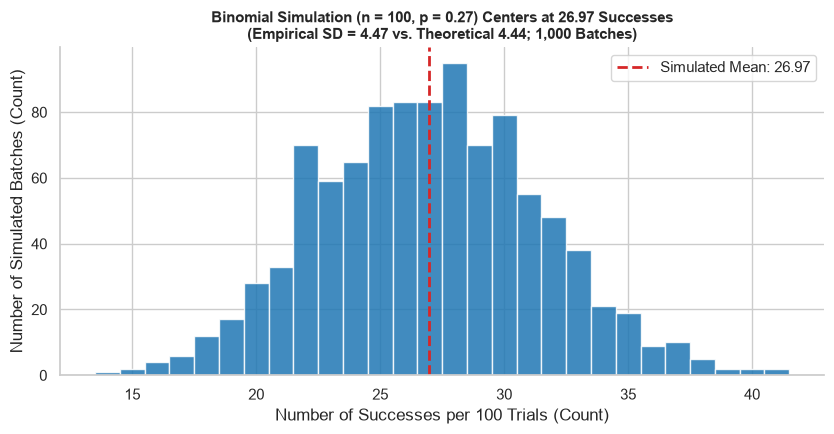

In [3]:
print("=== STEP 4: BINOMIAL MODEL (1,000 BATCHES OF n = 100 AT p = 0.27) ===")

# --- ORIGINAL PREDICTION (STEP 4 — UNEDITED) ---
# Prediction (Binomial): Across 1,000 simulated batches of n = 100 trials with p = 0.27, the empirical mean will land right around n * p = 27.0 successes, and the empirical standard deviation will match sqrt(n * p * (1 - p)) = sqrt(100 * 0.27 * 0.73) ≈ 4.44 successes.

n_trials = 100
p_succ = 0.27
theo_binom_mean = n_trials * p_succ
theo_binom_sd = np.sqrt(n_trials * p_succ * (1 - p_succ))

rng = np.random.default_rng(42)
batches = rng.binomial(n=n_trials, p=p_succ, size=1000)

emp_binom_mean = float(batches.mean())
emp_binom_sd = float(batches.std(ddof=1))

print(f"Binomial(n={n_trials}, p={p_succ}) across 1,000 batches:")
print(f"Empirical Mean: {emp_binom_mean:.2f} (Theoretical n*p: {theo_binom_mean:.2f})")
print(f"Empirical SD:   {emp_binom_sd:.2f} (Theoretical sqrt(npq): {theo_binom_sd:.2f})")

fig, ax = plt.subplots(figsize=(8.5, 4.5))
bins_binom = np.arange(batches.min() - 0.5, batches.max() + 1.5, 1)
ax.hist(batches, bins=bins_binom, color='#1f77b4', edgecolor='white', alpha=0.85)
ax.axvline(emp_binom_mean, color='#d62728', linestyle='--', linewidth=2, label=f'Simulated Mean: {emp_binom_mean:.2f}')
finish(
    ax,
    f'Binomial Simulation (n = {n_trials}, p = {p_succ}) Centers at {emp_binom_mean:.2f} Successes\n(Empirical SD = {emp_binom_sd:.2f} vs. Theoretical {theo_binom_sd:.2f}; 1,000 Batches)',
    'Number of Successes per 100 Trials (Count)',
    'Number of Simulated Batches (Count)'
)
ax.legend()
fig.tight_layout()
plt.show()

# Result check (Step 4): Predicted mean ~27.0 and SD ~4.44; actual empirical mean across 1,000 batches is 26.97 (vs. theoretical 27.00) and empirical SD is 4.47 (vs. theoretical 4.44).


=== STEP 5: WHEN THE NORMAL MODEL FAILS ('gross_m' vs. 'score') ===
Box Office Gross (n = 7,479) -> Mean: $78.50M | SD: $165.73M | Skew: 5.31


,k_sd,normal_rule_pct,score_actual_pct,gross_m_actual_pct,gross_lower_bound_M,gross_upper_bound_M
0,1,68.3,69.3,91.8,-87.22,244.23
1,2,95.5,95.9,96.1,-252.95,409.95
2,3,99.7,99.2,97.7,-418.67,575.68


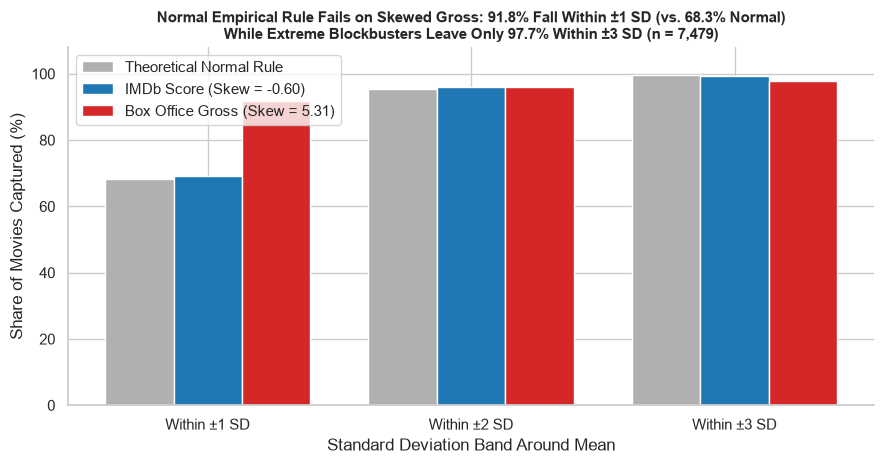

In [4]:
print("=== STEP 5: WHEN THE NORMAL MODEL FAILS ('gross_m' vs. 'score') ===")

# --- ORIGINAL PREDICTION (STEP 5 — UNEDITED) ---
# Prediction (gross_m empirical shares): Because 'gross_m' is heavily right-skewed (skew = 5.31) with an inflated SD ($165.73M) that is more than twice the mean ($78.50M), the 1-SD band will stretch from negative -$87M up to +$244M—capturing FAR ABOVE 68% of movies (likely 90%–95% within 1 SD, landing WELL ABOVE the score and normal shares at k = 1, and slightly below at k = 3 due to extreme $1B+ blockbusters).

g = movies['gross_m'].dropna()
n_gross = len(g)
g_mu = float(g.mean())
g_sd = float(g.std(ddof=1))
g_skew = float(g.skew())

comp_rows = []
for k in (1, 2, 3):
    s_share = float(((s > mu - k * sd) & (s < mu + k * sd)).mean()) * 100
    g_share = float(((g > g_mu - k * g_sd) & (g < g_mu + k * g_sd)).mean()) * 100
    comp_rows.append({
        'k_sd': k,
        'normal_rule_pct': round(normal_bench[k] * 100, 1),
        'score_actual_pct': round(s_share, 1),
        'gross_m_actual_pct': round(g_share, 1),
        'gross_lower_bound_M': round(g_mu - k * g_sd, 2),
        'gross_upper_bound_M': round(g_mu + k * g_sd, 2)
    })

comp_df = pd.DataFrame(comp_rows)
print(f"Box Office Gross (n = {n_gross:,}) -> Mean: ${g_mu:.2f}M | SD: ${g_sd:.2f}M | Skew: {g_skew:.2f}")
display(comp_df)

# Side-by-side grouped bar chart contrasting Normal Rule vs. Score vs. Gross_m at 1, 2, and 3 SDs
fig, ax = plt.subplots(figsize=(9, 4.8))
x_pos = np.arange(3)
width = 0.26

ax.bar(x_pos - width, comp_df['normal_rule_pct'], width=width, color='#b0b0b0', label='Theoretical Normal Rule')
ax.bar(x_pos, comp_df['score_actual_pct'], width=width, color='#1f77b4', label=f'IMDb Score (Skew = {sk_score:.2f})')
ax.bar(x_pos + width, comp_df['gross_m_actual_pct'], width=width, color='#d62728', label=f'Box Office Gross (Skew = {g_skew:.2f})')

g1_actual = float(comp_df.loc[comp_df['k_sd'] == 1, 'gross_m_actual_pct'].squeeze())
g3_actual = float(comp_df.loc[comp_df['k_sd'] == 3, 'gross_m_actual_pct'].squeeze())

ax.set_xticks(x_pos)
ax.set_xticklabels(['Within ±1 SD', 'Within ±2 SD', 'Within ±3 SD'])
ax.set_ylim(0, 108)
finish(
    ax,
    f'Normal Empirical Rule Fails on Skewed Gross: {g1_actual:.1f}% Fall Within ±1 SD (vs. 68.3% Normal)\nWhile Extreme Blockbusters Leave Only {g3_actual:.1f}% Within ±3 SD (n = {n_gross:,})',
    'Standard Deviation Band Around Mean',
    'Share of Movies Captured (%)'
)
ax.legend()
fig.tight_layout()
fig.savefig('empirical_rule_score_vs_gross.png', dpi=200)
plt.show()

# Result check (Step 5): Predicted gross_m would land WELL ABOVE score within ±1 SD (~90%–95%) due to the impossible negative lower bound (-$87.22M) and slightly below at ±3 SD; actual gross_m shares are 91.8% within ±1 SD (vs. 69.3% for score and 68.3% Normal), 96.1% within ±2 SD (vs. 95.9% score), and 97.7% within ±3 SD (below 99.2% score and 99.7% Normal due to 2.3% of blockbusters exceeding $575.68M).
